# Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q -U keras-tuner
!pip install -q visualkeras
!pip install -q corner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 51.8 MB/s eta 0:00:00


In [ ]:
# --- Standard library imports ----------------------------------------------------
import os
from tqdm import trange

# --- Third-party scientific computing libraries ---------------------------------
import numpy as np
import pandas as pd
from math import ceil

# --- Machine learning libraries -------------------------------------------------
import tensorflow as tf
import kerastuner as kt

# --- Preprocessing and data utilities from scikit-learn -------------------------
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

# --- Visualization libraries ----------------------------------------------------
import corner
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import matplotlib.gridspec as gridspec
from PIL import ImageFont
import visualkeras

# --- Matplotlib global style configuration --------------------------------------
plt.rcParams.update({
    "xtick.top": True,
    "ytick.right": True,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "font.size": 14,
    "font.family": "sans-serif",

    # Axis labels and titles
    "axes.labelsize": 14,
    "axes.titlesize": 14,

    # Legend style
    "legend.fontsize": 12,
    "legend.frameon": False,

    # Tick label sizes
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,

    # Minor ticks visibility
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,

    # Major tick sizes (length of tick marks)
    "xtick.major.size": 6,
    "ytick.major.size": 6,

    # Minor tick sizes
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,

    # Optional grid and spines customization
    # "axes.spines.top": False,
    # "axes.spines.right": False,
    # "axes.grid": True,
    # "grid.color": "gray",
    # "grid.linestyle": "--",
    # "grid.linewidth": 0.5,
    # "grid.alpha": 0.3,
})

# Looking the data

In [ ]:
# --- Define the folder path where the parquet files are stored ------------------
FOLDER_PATH = "/content/drive/MyDrive/retrieval-m-stars/data/data/"

# --- List all parquet files in the target folder --------------------------------
parquet_file_paths = [os.path.join(FOLDER_PATH, file_name) for file_name in os.listdir(FOLDER_PATH) if file_name.endswith(".parquet")]

# --- Read all parquet files and combine into a single DataFrame -----------------
df = pd.concat([pd.read_parquet(file_path) for file_path in parquet_file_paths], ignore_index=True)

In [ ]:
# --- Looking the five first data point ------------------
df.head()

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun,wavelength_A,flux,continuum
0,3018.919882,4.018751,0.176489,0.079048,0.455062,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9996236562728882, 0.9996230006217957, 0.999...","[544101.75, 544101.6875, 544101.6875, 544101.6..."
1,3052.943637,4.672465,-0.327704,0.127742,0.272543,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9996432662010193, 0.9996426701545715, 0.999...","[509092.5, 509092.5, 509092.5, 509092.46875, 5..."
2,3232.621100,4.571937,-0.104838,0.346403,0.503874,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9994550347328186, 0.9994540214538574, 0.999...","[640880.0625, 640879.875, 640879.6875, 640879...."
3,3310.135766,4.512431,-0.076281,0.357263,0.547998,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9993734955787659, 0.9993721842765808, 0.999...","[698381.625, 698381.375, 698381.125, 698380.87..."
4,3207.576568,4.629038,-0.023854,0.506044,0.570263,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.999427855014801, 0.9994267821311951, 0.9994...","[633054.25, 633054.0625, 633053.9375, 633053.7..."


In [ ]:
# --- We have 20 000 spectra with 8 features ------------------
df.shape

(20000, 8)

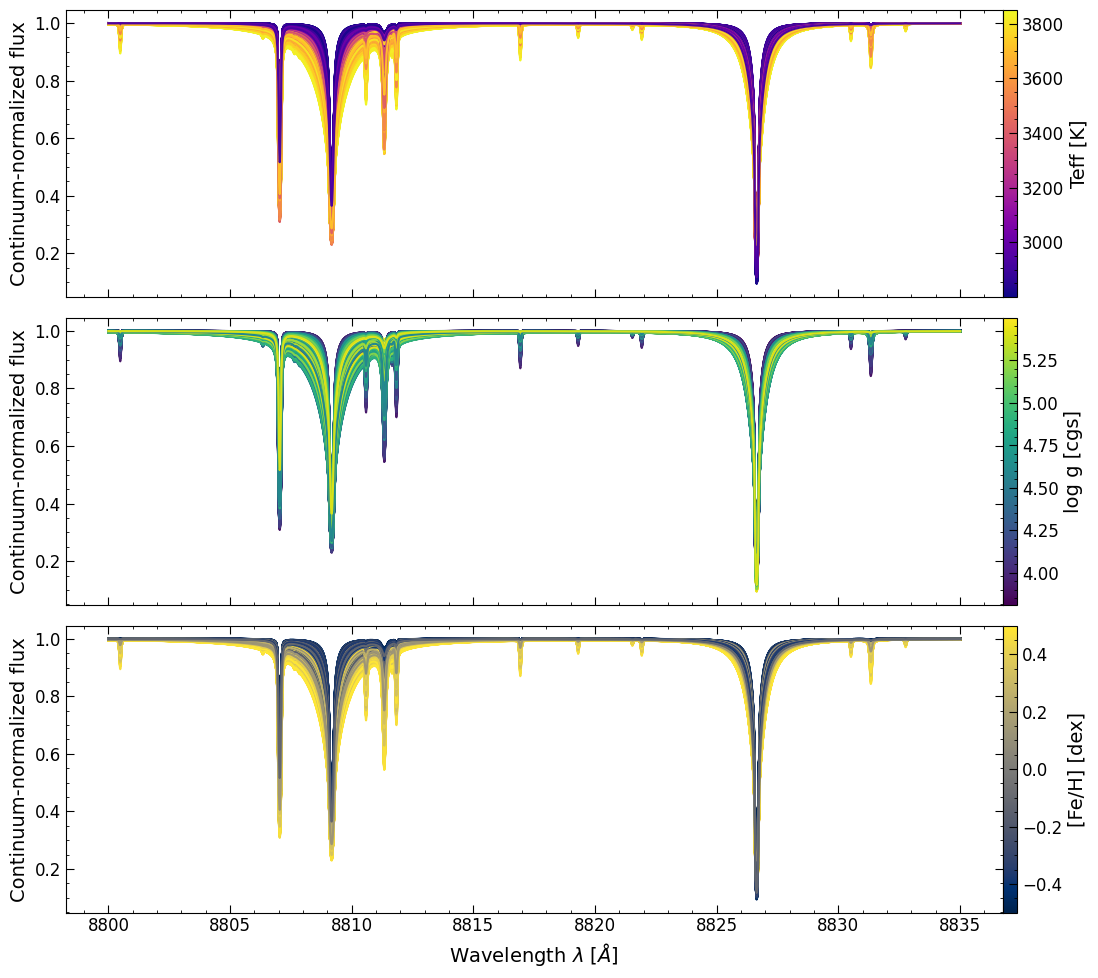

In [ ]:
# --- Plot: three stacks colored by Teff, log g, [Fe/H] --------------------------
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Panel 1 colored by Teff
norm_teff = Normalize(vmin=df["Teff_K"].min(), vmax=df["Teff_K"].max())
cmap_teff = plt.cm.plasma
for _, row in df.iterrows():
    axes[0].plot(np.asarray(row["wavelength_A"]), np.asarray(row["flux"]),
                color=cmap_teff(norm_teff(row["Teff_K"])))
sm = ScalarMappable(norm=norm_teff, cmap=cmap_teff)
fig.colorbar(sm, ax=axes[0], label="Teff [K]", pad=0)
axes[0].set_ylabel("Continuum-normalized flux")

# Panel 2 colored by log g
norm_logg = Normalize(vmin=df["logg_cgs"].min(), vmax=df["logg_cgs"].max())
cmap_logg = plt.cm.viridis
for _, row in df.iterrows():
    axes[1].plot(np.asarray(row["wavelength_A"]), np.asarray(row["flux"]),
                color=cmap_logg(norm_logg(row["logg_cgs"])))
sm = ScalarMappable(norm=norm_logg, cmap=cmap_logg)
fig.colorbar(sm, ax=axes[1], label="log g [cgs]", pad=0)
axes[1].set_ylabel("Continuum-normalized flux")

# Panel 3 colored by [Fe/H]
norm_feh = Normalize(vmin=df["FeH_dex"].min(), vmax=df["FeH_dex"].max())
cmap_feh = plt.cm.cividis
for _, row in df.iterrows():
    axes[2].plot(np.asarray(row["wavelength_A"]), np.asarray(row["flux"]),
                color=cmap_feh(norm_feh(row["FeH_dex"])))
sm = ScalarMappable(norm=norm_feh, cmap=cmap_feh)
fig.colorbar(sm, ax=axes[2], label="[Fe/H] [dex]", pad=0)

axes[2].set_xlabel(r"Wavelength $\lambda$ [$\AA$]")
axes[2].set_ylabel("Continuum-normalized flux")
plt.tight_layout()

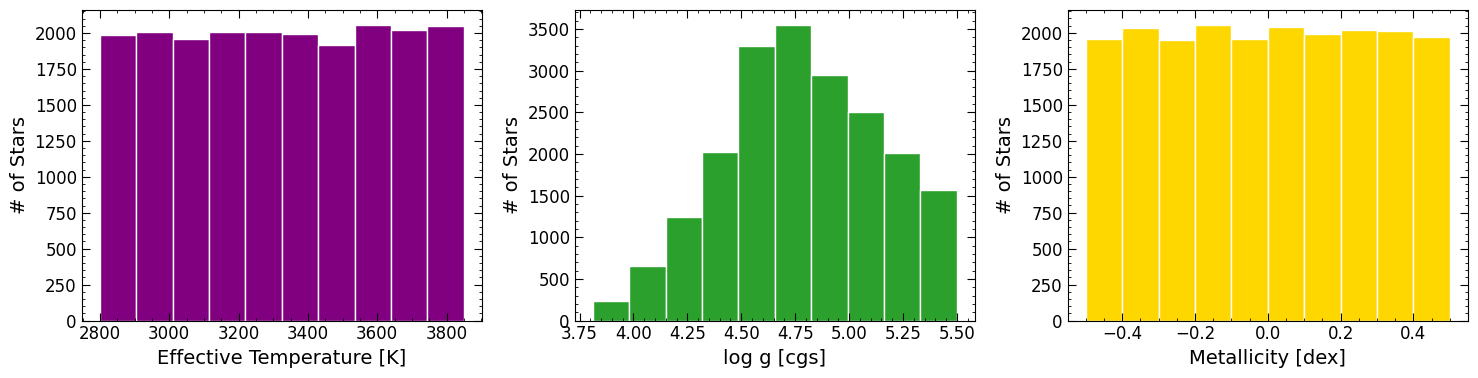

In [ ]:
cols = ["Teff_K", "logg_cgs", "FeH_dex"]
labels = ["Effective Temperature [K]", "log g [cgs]", "Metallicity [dex]"]
colors = ["purple", "tab:green", "gold"]

fig, axes = plt.subplots(1, len(cols), figsize=(15, 4))

for ax, col, color, label in zip(axes, cols, colors, labels):
    ax.hist(df[col], bins=10, edgecolor="white", color=color)
    ax.set_xlabel(label)
    ax.set_ylabel("# of Stars")

plt.tight_layout();

# Preprocessing data and creating the training and testing datasets

In [ ]:
# -- Define input and output variables -------------------------------------------
INPUT_FEATURE = "flux"                               # Column with spectra
OUTPUT_TARGETS = ["Teff_K", "logg_cgs", "FeH_dex"]   # Columns with labels to predict

# -- Prepare input matrix X and output matrix y ---------------------------------
X_features = np.stack(df[INPUT_FEATURE].values)  # Convert list of arrays into 2D NumPy array
y_targets = df[OUTPUT_TARGETS].copy()            # Copy DataFrame with target variables

# -- Split dataset: train, test, validation --------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X_features, y_targets, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=42)

In [ ]:
print("X shapes (INPUT):")
print("  - Train:", X_train.shape, f"({len(X_train)/len(X_features):.2%})")
print("  - Val:  ", X_val.shape, f"({len(X_val)/len(X_features):.2%})")
print("  - Test: ", X_test.shape, f"({len(X_test)/len(X_features):.2%})")

print("\ny shapes (OUTPUTS):")
print("  - Train:", y_train.shape, f"({len(y_train)/len(y_targets):.2%})")
print("  - Val:  ", y_val.shape, f"({len(y_val)/len(y_targets):.2%})")
print("  - Test: ", y_test.shape, f"({len(y_test)/len(y_targets):.2%})")

X shapes (INPUT):
  - Train: (16200, 3501) (81.00%)
  - Val:   (1800, 3501) (9.00%)
  - Test:  (2000, 3501) (10.00%)

y shapes (OUTPUTS):
  - Train: (16200, 3) (81.00%)
  - Val:   (1800, 3) (9.00%)
  - Test:  (2000, 3) (10.00%)


In [ ]:
# -- Target normalization (inputs already normalized, so only outputs are scaled) --
num_output_features = len(OUTPUT_TARGETS)     # Number of target variables to predict
output_scalers = []                           # List to store one StandardScaler per target

# Allocate arrays with same shape as original splits for scaled values
y_train_scaled = np.zeros_like(y_train, dtype=float)
y_val_scaled = np.zeros_like(y_val, dtype=float)
y_test_scaled = np.zeros_like(y_test, dtype=float)

# Fit scaler on train targets, then apply to validation and test
# Study: https://medium.com/@jeapsilva/quando-utilizar-standardscaler-minmaxscaler-e-robustscaler-em-machine-learning-788de8b157ca
for feature_idx in range(num_output_features):
    scaler = StandardScaler()
    train_column = y_train.to_numpy()[:, feature_idx].reshape(-1, 1)
    val_column = y_val.to_numpy()[:, feature_idx].reshape(-1, 1)
    test_column = y_test.to_numpy()[:, feature_idx].reshape(-1, 1)

    y_train_scaled[:, feature_idx] = scaler.fit_transform(train_column).ravel()
    y_val_scaled[:, feature_idx] = scaler.transform(val_column).ravel()
    y_test_scaled[:, feature_idx] = scaler.transform(test_column).ravel()

    output_scalers.append(scaler)

In [ ]:
# -- Reshape inputs to add channel dimension (needed for CNN) --------------------
X_train_expanded = X_train[..., np.newaxis]  # Shape: (n_samples, n_features, 1)
X_val_expanded   = X_val[..., np.newaxis]    # Shape: (n_samples, n_features, 1)
X_test_expanded  = X_test[..., np.newaxis]   # Shape: (n_samples, n_features, 1)

# -- Define input and output dimensions -----------------------------------------
input_shape  = X_train_expanded.shape[1:]    # Shape of a single input sample
output_units = y_train_scaled.shape[1]       # Number of target variables to predict

In [ ]:
# -- Just show you about the extra dimension ------
X_train_expanded.shape

(16200, 3501, 1)

In [ ]:
# -- Map each output variable to its corresponding scaled values -----------------
y_train_dict = {target_name: y_train_scaled[:, target_idx] for target_idx, target_name in enumerate(OUTPUT_TARGETS)}
y_val_dict = {target_name: y_val_scaled[:, target_idx] for target_idx, target_name in enumerate(OUTPUT_TARGETS)}
y_test_dict = {target_name: y_test_scaled[:, target_idx]for target_idx, target_name in enumerate(OUTPUT_TARGETS)}

In [ ]:
# -- Define batch size -----------------------------------------------------------
batch_size = 32   # "Batch" = a group of samples processed at the same time.
                  # Example: instead of training with 1 sample at a time,
                  # the model processes 32 together. This speeds up training
                  # and makes gradient updates more stable.

# -- Parsing function: cast inputs/outputs to float32 ----------------------------
def _parse_function(x, y):
    # Ensure that all features and labels are float32
    # (standard datatype in TensorFlow for GPU/CPU training).
    x = tf.cast(x, tf.float32)
    y = {name: tf.cast(val, tf.float32) for name, val in y.items()}
    return x, y

# -- Training dataset ------------------------------------------------------------
# Create the dataset from numpy arrays (features and labels).
train_dataset = tf.data.Dataset.from_tensor_slices((X_train_expanded, y_train_dict))

# "map" applies the _parse_function to every sample.
# AUTOTUNE lets TensorFlow decide the optimal number of parallel calls.
train_dataset = train_dataset.map(_parse_function, num_parallel_calls=tf.data.AUTOTUNE)

# "shuffle" randomizes the order of the samples.
# buffer_size=1000 means it keeps 1000 samples in memory and picks randomly from them.
# Shuffling prevents the model from memorizing the original order of the data.
train_dataset = train_dataset.shuffle(buffer_size=1000)

# "batch" groups samples into mini-batches of 32 (defined above).
train_dataset = train_dataset.batch(batch_size)

# "prefetch" prepares the next batch while the current one is being processed.
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)

# -- Validation dataset ----------------------------------------------------------
validation_dataset = tf.data.Dataset.from_tensor_slices((X_val_expanded, y_val_dict))
validation_dataset = validation_dataset.map(_parse_function, num_parallel_calls=tf.data.AUTOTUNE)
validation_dataset = validation_dataset.batch(batch_size)
validation_dataset = validation_dataset.prefetch(tf.data.AUTOTUNE)

# -- Test dataset ----------------------------------------------------------------
test_dataset = tf.data.Dataset.from_tensor_slices((X_test_expanded, y_test_dict))
test_dataset = test_dataset.map(_parse_function, num_parallel_calls=tf.data.AUTOTUNE)
test_dataset = test_dataset.batch(batch_size)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

# Convolutional Neural Network 1D (CNN) with tuning hyperparameters

In [ ]:
# Vou escrever as coisas em português para que você entenda de verdade.

# -------------------------------------------------------------------------------
# Wrappers de Dropout para Monte Carlo (MC Dropout)
# Dropout é uma técnica de regularização que "desliga" aleatoriamente neurônios
# durante o treinamento. Aqui estamos forçando que o Dropout continue ativo
# também na fase de inferência (predição), o que gera incertezas estatísticas.
# Isso é conhecido como "Monte Carlo Dropout" e é usado para estimar incerteza.
# -------------------------------------------------------------------------------
class MCDropout(tf.keras.layers.Dropout):
    def call(self, inputs, training=None):
        # Mesmo em inferência, forçamos training=True
        return super().call(inputs, training=True)

class SpatialMCDropout(tf.keras.layers.SpatialDropout1D):
    def call(self, inputs, training=None):
        # O mesmo, mas para camadas de dropout espacial (1D, para espectros)
        return super().call(inputs, training=True)


# -------------------------------------------------------------------------------
# Classe principal: CNN com ajuste de hiperparâmetros usando Otimização Bayesiana
# e MC Dropout para incertezas.
# CNN (Convolutional Neural Network) é uma rede que aplica filtros convolucionais
# em dados sequenciais ou imagens para extrair padrões locais.
# -------------------------------------------------------------------------------
class HyperTuningBayCNN:
    def __init__(self, input_shape, output_units=1, outputs_list=None):
        # input_shape: formato de uma amostra de entrada (ex.: comprimento do espectro, nº de canais)
        # output_units: número de saídas (pode ser int ou dict para saídas múltiplas)
        # outputs_list: nomes das variáveis de saída
        self.input_shape = input_shape
        self.output_units = output_units
        self.outputs_list = outputs_list or []
        self.best_hps = None      # Armazena os melhores hiperparâmetros encontrados
        self.best_model = None    # Armazena o melhor modelo treinado
        self.history = None       # Histórico de treino (perdas por época)

    # ---------------------------------------------------------------------------
    # Função auxiliar: retorna quantas unidades (neurônios) usar em cada saída.
    # Se for dict, pega por nome da saída. Se for int, usa direto.
    # ---------------------------------------------------------------------------
    def _units_for_output(self, output_name):
        if isinstance(self.output_units, dict):
            return int(self.output_units.get(output_name, 1))
        try:
            return int(self.output_units)
        except Exception:
            return 1

    # ---------------------------------------------------------------------------
    # Construção do modelo CNN com hiperparâmetros ajustáveis.
    # Hiperparâmetros (HPs): variáveis que controlam arquitetura e treino,
    # como nº de filtros, tamanho de kernel, nº de camadas, taxa de dropout etc.
    # Aqui usamos o objeto "hp" (do Keras Tuner) para definir faixas de busca.
    # ---------------------------------------------------------------------------
    def build_model(self, hp):
        # Entrada
        inputs = tf.keras.Input(shape=self.input_shape)
        x = inputs

        # Blocos convolucionais
        conv_blocks = hp.Int('conv_blocks', 1, 3)  # nº de blocos convolucionais
        for b in range(conv_blocks):
            # Primeira convolução do bloco
            x = tf.keras.layers.Conv1D(
                filters=hp.Int(f'filters_b{b}_a', 16, 128, step=16),  # nº de filtros
                kernel_size=hp.Choice(f'kernel_b{b}_a_ks', values=[3, 5, 7, 9]),  # tamanho do kernel
                padding='same',
                activation='swish'  # função de ativação suave e moderna
            )(x)

            # Segunda convolução do bloco
            x = tf.keras.layers.Conv1D(
                filters=hp.Int(f'filters_b{b}_b', 16, 128, step=16),
                kernel_size=hp.Choice(f'kernel_b{b}_b_ks', values=[3, 5, 7, 9]),
                padding='same',
                activation='swish'
            )(x)

            # MaxPooling reduz a dimensão da entrada (downsampling), mantendo padrões
            x = tf.keras.layers.MaxPooling1D(pool_size=2)(x)
            # Normalização em batch: estabiliza e acelera o treino
            x = tf.keras.layers.BatchNormalization()(x)
            # Dropout espacial (desliga filtros inteiros, não apenas neurônios individuais)
            x = SpatialMCDropout(
                rate=hp.Float(f'dropout_rate_conv_b{b}', 0.0, 0.5, step=0.1)
            )(x)

        # Flatten: achata o tensor em vetor para passar para camadas densas
        x = tf.keras.layers.Flatten()(x)

        # Blocos densos (camadas totalmente conectadas)
        dense_blocks = hp.Int('dense_layers', 1, 3)
        for d in range(dense_blocks):
            x = tf.keras.layers.Dense(
                units=hp.Int(f'units_dense_{d}', 64, 512, step=64),  # nº de neurônios
                activation='swish',
                kernel_regularizer=tf.keras.regularizers.l2(1e-5)  # regularização L2
            )(x)
            # Dropout normal (com MC Dropout)
            x = MCDropout(hp.Float(f'dropout_rate_dense_{d}', 0.0, 0.5, step=0.1))(x)

        # Camadas de saída: uma por variável alvo
        outputs = {}
        for output_name in self.outputs_list:
            units = self._units_for_output(output_name)
            outputs[output_name] = tf.keras.layers.Dense(
                units=units, activation='linear',  # saída linear para regressão
                kernel_regularizer=tf.keras.regularizers.l1(1e-5),
                name=output_name
            )(x)

        model = tf.keras.Model(inputs=inputs, outputs=outputs)

        # Agendamento da taxa de aprendizado: Cosine Decay Restarts
        lr = hp.Float('learning_rate', 1e-5, 1e-2, sampling='log')
        lr_schedule = tf.keras.optimizers.schedules.CosineDecayRestarts(
            initial_learning_rate=lr,
            first_decay_steps=10,
            t_mul=2.0, m_mul=0.9, alpha=0.1
        )

        # Compilação do modelo (define otimizador e função de perda)
        losses = {name: 'mse' for name in self.outputs_list}  # regressão (MSE)
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
            loss=losses
        )
        return model

    # ---------------------------------------------------------------------------
    # Busca de hiperparâmetros usando Bayesian Optimization (mais eficiente que grid search)
    # ---------------------------------------------------------------------------
    def search(self, train_dataset, validation_dataset, max_trials=50, search_epochs=3):
        tuner = kt.BayesianOptimization(
            self.build_model, objective="val_loss",
            max_trials=max_trials,
            directory=f"{FOLDER_PATH}/hyperparam_search",
            project_name="cnn_bay_tuning"
        )
        tuner.search(train_dataset, validation_data=validation_dataset, epochs=search_epochs)
        self.best_hps = tuner.get_best_hyperparameters(1)[0]
        return self.best_hps

    # ---------------------------------------------------------------------------
    # Treina o melhor modelo encontrado (com EarlyStopping para evitar overfitting)
    # ---------------------------------------------------------------------------
    def fit_best_model(self, train_dataset, validation_dataset, epochs=100, patience=5):
        if not self.best_hps:
            raise ValueError("No best hyperparameters found. Run 'search' first.")

        self.best_model = self.build_model(self.best_hps)
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=patience, restore_best_weights=True
        )
        self.history = self.best_model.fit(
            train_dataset, epochs=epochs,
            validation_data=validation_dataset,
            callbacks=[early_stopping], verbose=1
        )
        return self.best_model, self.history

    # ---------------------------------------------------------------------------
    # Avaliação em conjunto de teste: retorna métricas + gráficos de dispersão
    # ---------------------------------------------------------------------------
    def evaluate(self, test_dataset, feature_names, y_scalers, plot=True, additional_metrics=True):
        if self.best_model is None:
            raise ValueError("No trained model. Run 'fit_best_model' first.")

        # collect true and predicted outputs
        y_true_dict = {name: [] for name in self.outputs_list}
        y_pred_dict = {name: [] for name in self.outputs_list}

        for X_batch, y_batch in test_dataset:
            preds = self.best_model.predict(X_batch, verbose=0)
            if isinstance(preds, dict):
                pred_batch = preds
            elif isinstance(preds, (list, tuple)):
                pred_batch = {name: preds[idx] for idx, name in enumerate(self.outputs_list)}
            else:
                pred_batch = {self.outputs_list[0]: preds}

            for name in self.outputs_list:
                y_true_arr = y_batch[name].numpy() if tf.is_tensor(y_batch[name]) else np.array(y_batch[name])
                y_pred_arr = pred_batch[name]
                y_true_dict[name].extend(y_true_arr.reshape(-1).tolist())
                y_pred_dict[name].extend(np.asarray(y_pred_arr).reshape(-1).tolist())

        # stack outputs in consistent order
        y_true = np.column_stack([np.array(y_true_dict[n]) for n in self.outputs_list])
        y_pred = np.column_stack([np.array(y_pred_dict[n]) for n in self.outputs_list])

        # inverse-transform to original scale
        y_true_inv = np.column_stack([
            y_scalers[i].inverse_transform(y_true[:, i].reshape(-1, 1)).ravel()
            for i in range(len(self.outputs_list))
        ])
        y_pred_inv = np.column_stack([
            y_scalers[i].inverse_transform(y_pred[:, i].reshape(-1, 1)).ravel()
            for i in range(len(self.outputs_list))
        ])

        return self._evaluate_outputs(y_true_inv, y_pred_inv, feature_names, plot, additional_metrics)

    # ---------------------------------------------------------------------------
    # Avaliação com métricas estatísticas + scatter plots (previsão vs verdade)
    # ---------------------------------------------------------------------------
    def _evaluate_outputs(self, y_true, y_pred, feature_names, plot=True, show=True, save_path=None):
      y_true = np.asarray(y_true)
      y_pred = np.asarray(y_pred)
      num_outputs = y_true.shape[1]

      rows = []
      for i in range(num_outputs):
          yt = y_true[:, i]
          yp = y_pred[:, i]
          resid = yp - yt

          r2 = metrics.r2_score(yt, yp)
          mae = metrics.mean_absolute_error(yt, yp)
          mse = metrics.mean_squared_error(yt, yp)
          rmse = np.sqrt(mse)

          rows.append({
              'R2': round(r2, 3),
              'MAE': round(mae, 3),
              'MSE': round(mse, 3),
              'RMSE': round(rmse, 3)})

      results_df = pd.DataFrame(rows, index=feature_names)

      fig_axs = None
      if plot:
          num_cols = 3
          num_rows = max(1, ceil(num_outputs / num_cols))
          fig, axs = plt.subplots(num_rows, num_cols, figsize=(3 * num_cols, 3 * num_rows))
          axs_flat = np.array(axs).reshape(-1)

          for i in range(num_outputs):
              ax = axs_flat[i]
              yt = y_true[:, i]
              yp = y_pred[:, i]
              r2_label = results_df.loc[feature_names[i], 'R2']
              ax.scatter(yt, yp, label=f'R² = {r2_label}', alpha=0.6)
              ax.plot([yt.min(), yt.max()], [yt.min(), yt.max()], ls="--")
              ax.set_xlabel(f'True {feature_names[i]}')
              ax.set_ylabel(f'Predicted {feature_names[i]}')
              ax.legend()

          for i in range(num_outputs, num_rows * num_cols):
              fig.delaxes(axs_flat[i])

          fig.tight_layout()
          if save_path:
              os.makedirs(os.path.dirname(save_path), exist_ok=True)
              fig.savefig(save_path, dpi=100, bbox_inches='tight')
          if show:
              plt.show()
          fig_axs = (fig, axs_flat)

      return (results_df, fig_axs) if plot else (results_df, None)


    # ---------------------------------------------------------------------------
    # Plota evolução da função de perda (treino vs validação)
    # ---------------------------------------------------------------------------
    def plot_losses(self, show=True, save_path=None):
      if self.history is None:
          raise ValueError("No training history found. Train the model first.")

      fig, ax = plt.subplots()
      ax.plot(self.history.history.get('loss', []), label='Training loss')
      ax.plot(self.history.history.get('val_loss', []), label='Validation loss')
      ax.set_xlabel('Epochs')
      ax.set_ylabel('Loss')
      ax.legend()
      fig.tight_layout()

      if save_path:
          os.makedirs(os.path.dirname(save_path), exist_ok=True)
          fig.savefig(save_path, bbox_inches='tight')

      if show:
          plt.show()

      return fig, ax

    # ---------------------------------------------------------------------------
    # Mostra resumo do modelo (camadas, nº de parâmetros)
    # ---------------------------------------------------------------------------
    def summary(self):
        if self.best_model is None:
            print("No model is built yet. Train or load a model first.")
        else:
            self.best_model.summary()

In [ ]:
# -------------------------------------------------------------------------------
# Inicialização do objeto de tuning da CNN
# Aqui criamos uma instância da classe HyperTuningBayCNN, que contém toda a lógica
# para construir, ajustar hiperparâmetros e treinar a rede.
# input_shape : formato da entrada (ex.: (comprimento do espectro, nº de canais))
# outputs_list : lista com os nomes das variáveis de saída que o modelo deve prever.
# -------------------------------------------------------------------------------
cnn_tuner = HyperTuningBayCNN(input_shape=input_shape, outputs_list=OUTPUT_TARGETS)

In [ ]:
# -------------------------------------------------------------------------------
# Busca de hiperparâmetros (Otimização Bayesiana)
# Essa etapa explora diferentes combinações de hiperparâmetros (nº de filtros,
# tamanho dos kernels, nº de camadas densas, taxa de dropout, etc.).
# - max_trials=10 : número máximo de combinações a serem testadas.
# - search_epochs=2 : número de épocas de treino por tentativa.
# Observação: aqui o treino é curto, apenas para avaliar rapidamente as opções.
# Depois, o melhor modelo será treinado de verdade por mais épocas.
# -------------------------------------------------------------------------------
best_hps = cnn_tuner.search(
    train_dataset,
    validation_dataset,
    max_trials=20,
    search_epochs=2
)

Trial 20 Complete [00h 00m 26s]
val_loss: 3.0253419876098633

Best val_loss So Far: 0.26046615839004517
Total elapsed time: 00h 12m 32s


In [ ]:
# Exibir os valores encontrados para os melhores hiperparâmetros.
# Isso mostra, por exemplo, qual foi a melhor taxa de dropout, quantos filtros etc.
best_hps.values

{'conv_blocks': 2,
 'filters_b0_a': 96,
 'kernel_b0_a_ks': 5,
 'filters_b0_b': 16,
 'kernel_b0_b_ks': 5,
 'dropout_rate_conv_b0': 0.2,
 'dense_layers': 1,
 'units_dense_0': 448,
 'dropout_rate_dense_0': 0.0,
 'learning_rate': 0.0003372542176716235,
 'filters_b1_a': 48,
 'kernel_b1_a_ks': 9,
 'filters_b1_b': 48,
 'kernel_b1_b_ks': 9,
 'dropout_rate_conv_b1': 0.0,
 'filters_b2_a': 96,
 'kernel_b2_a_ks': 5,
 'filters_b2_b': 64,
 'kernel_b2_b_ks': 3,
 'dropout_rate_conv_b2': 0.4,
 'units_dense_1': 128,
 'dropout_rate_dense_1': 0.2,
 'units_dense_2': 320,
 'dropout_rate_dense_2': 0.2}

In [ ]:
# -------------------------------------------------------------------------------
# Treinamento do melhor modelo encontrado
# Agora usamos os melhores hiperparâmetros selecionados na etapa anterior para
# treinar a rede de forma mais robusta:
# - epochs=50 : até 50 épocas de treino (iterações sobre o dataset completo).
# - patience=8 : se a validação não melhorar após 8 épocas, para cedo (early stopping).
# O retorno é o melhor modelo treinado + histórico de treino (curvas de perda).
# -------------------------------------------------------------------------------
best_model, history = cnn_tuner.fit_best_model(
    train_dataset,
    validation_dataset,
    epochs=100,
    patience=8
)

Epoch 1/100
507/507 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - FeH_dex_loss: 0.7275 - Teff_K_loss: 5.6135 - logg_cgs_loss: 1.6126 - loss: 7.9634 - val_FeH_dex_loss: 0.8311 - val_Teff_K_loss: 0.6811 - val_logg_cgs_loss: 1.0049 - val_loss: 2.5192
Epoch 2/100
507/507 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - FeH_dex_loss: 0.0507 - Teff_K_loss: 0.0195 - logg_cgs_loss: 0.0369 - loss: 0.1171 - val_FeH_dex_loss: 0.1017 - val_Teff_K_loss: 0.0295 - val_logg_cgs_loss: 0.0359 - val_loss: 0.1779
Epoch 3/100
507/507 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - FeH_dex_loss: 0.0148 - Teff_K_loss: 0.0060 - logg_cgs_loss: 0.0098 - loss: 0.0407 - val_FeH_dex_loss: 0.0522 - val_Teff_K_loss: 0.0147 - val_logg_cgs_loss: 0.0501 - val_loss: 0.1274
Epoch 4/100
507/507 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - FeH_dex_loss: 0.0115 - Teff_K_loss: 0.0051 - logg_cgs_loss: 0.0097 - loss: 0.0363 - val_FeH_dex_loss: 0.0095 - val_Teff_K_loss: 0.0037 - val_logg_cgs_loss: 0.0079 - val_loss: 0.0312
Epoch 5/100
507/507 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/st

In [ ]:
# -------------------------------------------------------------------------------
# Resumo da arquitetura do modelo
# Mostra na tela todas as camadas da rede, quantos parâmetros treináveis existem
# em cada camada, e o total de parâmetros da CNN.
# -------------------------------------------------------------------------------
cnn_tuner.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 3501, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 3501, 96)  │        576 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 3501, 16)  │      7,696 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 1750, 16)  │          0 │ conv1d_5[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1750, 16)  │         64 │ max_pooling1d_2[… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_mc_dropout… │ (None, 1750, 16)  │          0 │ batch_normalizat… │
│ (SpatialMCDropout)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 1750, 48)  │      6,960 │ spatial_mc_dropo… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 1750, 48)  │     20,784 │ conv1d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 875, 48)   │          0 │ conv1d_7[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 875, 48)   │        192 │ max_pooling1d_3[… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_mc_dropout… │ (None, 875, 48)   │          0 │ batch_normalizat… │
│ (SpatialMCDropout)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 42000)     │          0 │ spatial_mc_dropo… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 448)       │ 18,816,448 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mc_dropout_1        │ (None, 448)       │          0 │ dense_1[0][0]     │
│ (MCDropout)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FeH_dex (Dense)     │ (None, 1)         │        449 │ mc_dropout_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Teff_K (Dense)      │ (None, 1)         │        449 │ mc_dropout_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logg_cgs (Dense)    │ (None, 1)         │        449 │ mc_dropout_1[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 56,561,946 (215.77 MB)

 Trainable params: 18,853,939 (71.92 MB)

 Non-trainable params: 128 (512.00 B)

 Optimizer params: 37,707,879 (143.84 MB)

/usr/local/lib/python3.12/dist-packages/visualkeras/layered.py:86: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


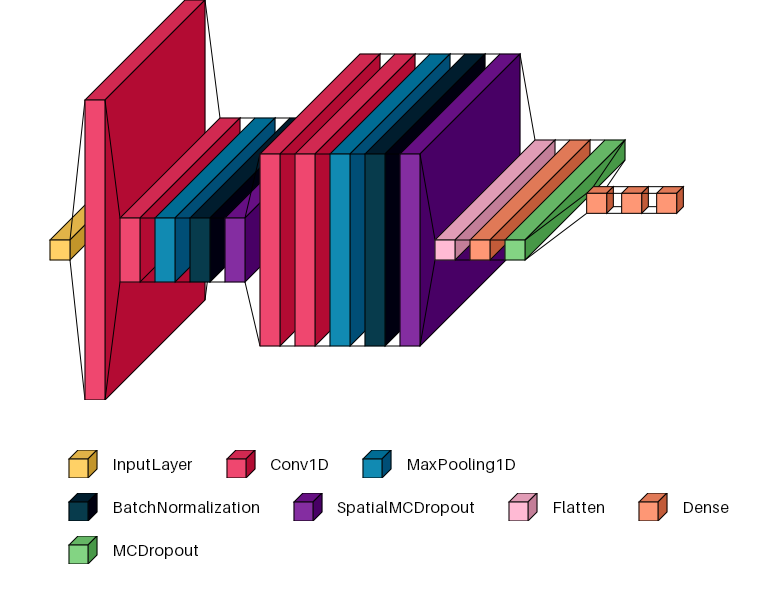

In [ ]:
# -------------------------------------------------------------------------------
# Visualizar a arquitetura do modelo
# O pacote "visualkeras" desenha uma representação gráfica das camadas da rede:
#   - Cada camada aparece como um bloco.
#   - A largura/altura podem representar filtros, unidades ou volume de dados.
# -------------------------------------------------------------------------------

font = ImageFont.load_default(size = 16)

visualkeras.layered_view(cnn_tuner.best_model, to_file='model_architecture.png', legend=True,
                        draw_funnel=True, draw_volume=True,
                        one_dim_orientation="x", max_xy=300, max_z=100, font=font, padding=50, spacing=15, shade_step=30)

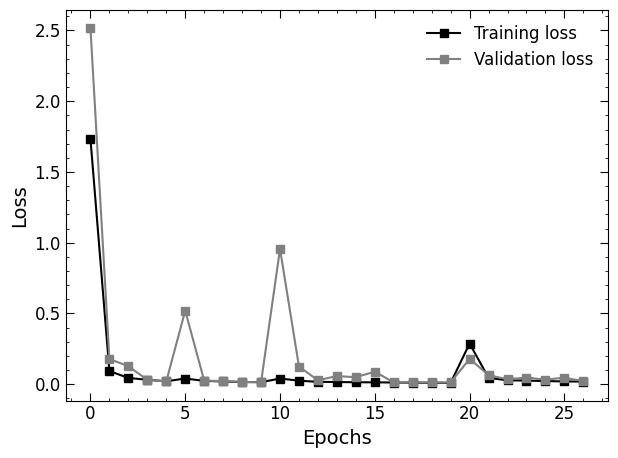

In [ ]:
# -------------------------------------------------------------------------------
# Plotar as curvas de perda (loss) do treino
# Essa função desenha duas curvas:
# - "Training loss": erro no conjunto de treino.
# - "Validation loss": erro no conjunto de validação.
# O gráfico ajuda a identificar:
#   Overfitting : quando a perda de treino continua caindo mas a de validação sobe.
#   Underfitting : quando ambas as perdas ficam altas.
#   Convergência : quando ambas estabilizam em valores baixos.
# -------------------------------------------------------------------------------
fig, ax = cnn_tuner.plot_losses(show=False)

# define estilos desejados
styles = [("o-", "black"), ("o-", "gray")]

for line, (style, color) in zip(ax.get_lines(), styles):
    line.set_linestyle("-")   # só linha contínua
    line.set_marker("s")      # marcador
    line.set_color(color)     # cor

# força atualização da legenda
ax.legend([line for line in ax.get_lines()],
          ["Training loss", "Validation loss"])

fig.canvas.draw();

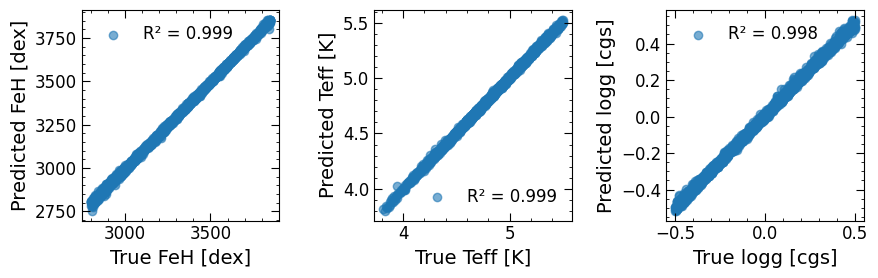

In [ ]:
names = ["FeH [dex]", "Teff [K]", "logg [cgs]"]

# -------------------------------------------------------------------------------
# Avaliar o modelo treinado no conjunto de teste
# A função "evaluate" faz o seguinte:
#   1. Coleta as predições e valores verdadeiros.
#   2. Inverte a normalização (volta para escala original).
#   3. Calcula métricas estatísticas de regressão (R², MAE, MSE, RMSE).
# -------------------------------------------------------------------------------
results, fig_axs = cnn_tuner.evaluate(test_dataset, feature_names=names,y_scalers=output_scalers,plot=True)

In [ ]:
results

,R2,MAE,MSE,RMSE
FeH [dex],0.999,6.418,72.357,8.506
Teff [K],0.999,0.010,0.000,0.013
logg [cgs],0.998,0.010,0.000,0.014


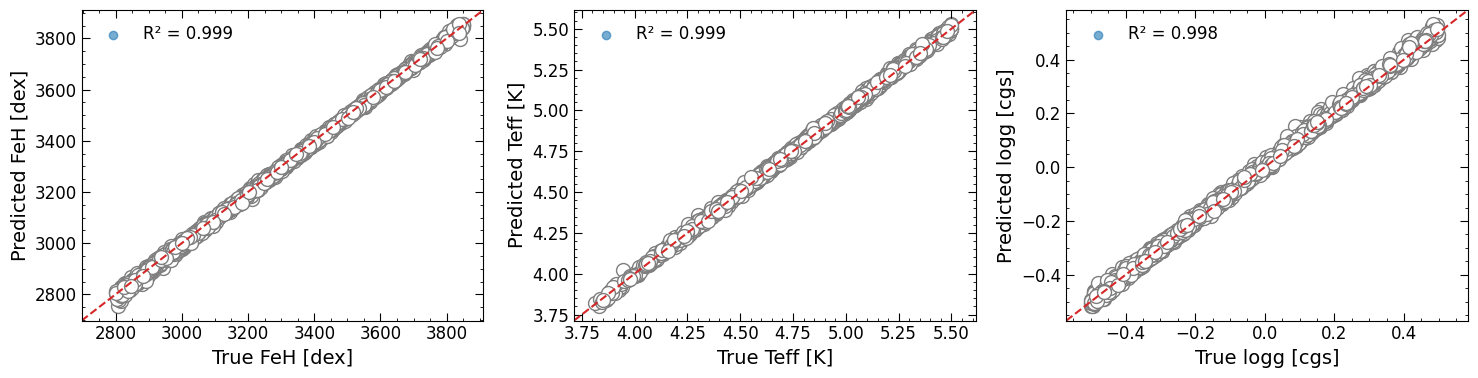

In [ ]:
# Ignore o gráfico acima, precisamos melhorar o estilo
from matplotlib.collections import PathCollection
fig, axs = fig_axs

def restyle_eval_axes(fig, axs):
    axs = np.ravel(axs)
    for ax in axs:
        if ax not in fig.axes:
            continue
        # pontos cinza com borda branca
        for coll in ax.collections:
            if isinstance(coll, PathCollection):
                coll.set_facecolor("white")   # cinza
                coll.set_edgecolor("tab:gray")                # borda branca
                coll.set_linewidth(1.0)
                coll.set_alpha(1.0)
                coll.set_sizes([100])
        # remover linha antiga y=x
        for line in list(ax.lines):
            x = np.asarray(line.get_xdata()); y = np.asarray(line.get_ydata())
            if x.size >= 2:
                A = np.vstack([x, np.ones_like(x)]).T
                m, b = np.linalg.lstsq(A, y, rcond=None)[0]
                if abs(m - 1.0) < 1e-6 and abs(b) < 1e-6:
                    line.remove()
        # nova linha 1:1 vermelha
        xlim, ylim = ax.get_xlim(), ax.get_ylim()
        lo = min(xlim[0], ylim[0]); hi = max(xlim[1], ylim[1])
        ax.plot([lo, hi], [lo, hi], color='tab:red', ls="--")
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)

    # aumentar tamanho do gráfico
    fig.set_size_inches(15, 4)   # ajuste os valores como quiser
    fig.tight_layout()
    fig.canvas.draw_idle()

restyle_eval_axes(fig, axs)
display(fig)
fig.savefig("avaliacao.png", dpi=400, bbox_inches="tight")

In [ ]:
cnn_tuner.best_model.save(f'{FOLDER_PATH}/model.keras')

- Trabalhos futuros:
   - Adicionar mais complexidade (moléculas)
   - Como já tem as camadas de dropout com incertezas ativas, calcular as distribuição a posteriori